#Name-Pranshul Modani

#B24-56

#SI Lab-Project

# Regression – Medical Insurance Cost Prediction



## Step 0: Install & Import Required Libraries

In [ ]:
!pip install beautifulsoup4 lxml requests pandas numpy matplotlib seaborn scipy -q

In [ ]:
import requests
from bs4 import BeautifulSoup
from io import StringIO
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style("whitegrid")
%matplotlib inline

## Web Scraping: Collect the Dataset from a Website


In [ ]:
url = "https://www.statlect.com/datasets/SimpleR-Pre-loaded-Medical-insurance-costs.csv"
backup_url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"

headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}

def fetch_csv(target_url):
    resp = requests.get(target_url, headers=headers, timeout=15)
    resp.raise_for_status()
    data = pd.read_csv(StringIO(resp.text))
    if data.empty or data.shape[0] < 10:
        raise ValueError("Downloaded dataset looks empty or too small")
    return data

try:
    df = fetch_csv(url)
    print("Data successfully SCRAPED from:", url)
except Exception as e:
    print("Primary source failed ({}). Using backup source instead.".format(e))
    df = fetch_csv(backup_url)

# Save the scraped data locally as CSV
df.to_csv("insurance.csv", index=False)
print("Saved as insurance.csv | Shape:", df.shape)
assert df.shape[0] > 0, "Dataset is empty!"
df.head(10)

Data successfully SCRAPED from: https://www.statlect.com/datasets/SimpleR-Pre-loaded-Medical-insurance-costs.csv
Saved as insurance.csv | Shape: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
5,31,female,25.740,0,no,southeast,3756.62160
6,46,female,33.440,1,no,southeast,8240.58960
7,37,female,27.740,3,no,northwest,7281.50560
8,37,male,29.830,2,no,northeast,6406.41070
9,60,female,25.840,0,no,northwest,28923.13692


# Practical 3 – Part A: Import, Clean & Describe the Data

### Task A1: Import the Dataset into Python

In [ ]:
df = pd.read_csv("insurance.csv")
print("Shape of dataset:", df.shape)
df.head(10)

Shape of dataset: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
5,31,female,25.740,0,no,southeast,3756.62160
6,46,female,33.440,1,no,southeast,8240.58960
7,37,female,27.740,3,no,northwest,7281.50560
8,37,male,29.830,2,no,northeast,6406.41070
9,60,female,25.840,0,no,northwest,28923.13692


### Task A2: Basic Info & Data Types

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


### Task A3: Data Cleaning – Check & Handle Missing Values

In [ ]:
print("Missing values in each column:\n")
print(df.isnull().sum())

# If any missing values exist, fill/drop them (none expected in this dataset)
df = df.dropna()
print("\nShape after handling missing values:", df.shape)

Missing values in each column:

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Shape after handling missing values: (1338, 7)


### Task A4: Data Cleaning – Check & Remove Duplicate Rows

In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Number of duplicate rows: 1
Shape after removing duplicates: (1337, 7)


### Task A5: Data Preprocessing – Fix Data Types & Standardize Text

In [ ]:
df['sex'] = df['sex'].str.lower().str.strip()
df['smoker'] = df['smoker'].str.lower().str.strip()
df['region'] = df['region'].str.lower().str.strip()

df['age'] = df['age'].astype(int)
df['children'] = df['children'].astype(int)
df['bmi'] = df['bmi'].astype(float)
df['charges'] = df['charges'].astype(float)

print(df.dtypes)
df.head()

age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


### Task A6: Measures of Central Tendency – Mean & Median

In [ ]:
numeric_cols = ['age', 'bmi', 'children', 'charges']

for col in numeric_cols:
    print(f"--- {col} ---")
    print("Mean   :", df[col].mean())
    print("Median :", df[col].median())
    print()

--- age ---
Mean   : 39.222139117427076
Median : 39.0

--- bmi ---
Mean   : 30.66345175766642
Median : 30.4

--- children ---
Mean   : 1.0957367240089753
Median : 1.0

--- charges ---
Mean   : 13279.121486655948
Median : 9386.1613



### Task A7: Measures of Dispersion – Variance & Standard Deviation

In [ ]:
for col in numeric_cols:
    print(f"--- {col} ---")
    print("Variance          :", df[col].var())
    print("Standard Deviation:", df[col].std())
    print("Range             :", df[col].max() - df[col].min())
    print()

--- age ---
Variance          : 197.2432819476976
Standard Deviation: 14.044332734156422
Range             : 46

--- bmi ---
Variance          : 37.21571481672034
Standard Deviation: 6.100468409615801
Range             : 37.17

--- children ---
Variance          : 1.4534024695560286
Standard Deviation: 1.2055714286412185
Range             : 5

--- charges ---
Variance          : 146660811.00600868
Standard Deviation: 12110.359656344179
Range             : 62648.554110000005



### Task A8: Quartiles & Interquartile Range (IQR)

In [ ]:
for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q2 = df[col].quantile(0.50)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    print(f"--- {col} ---")
    print(f"Q1 (25%) : {q1}")
    print(f"Q2 (50%) : {q2}")
    print(f"Q3 (75%) : {q3}")
    print(f"IQR      : {iqr}")
    print()

--- age ---
Q1 (25%) : 27.0
Q2 (50%) : 39.0
Q3 (75%) : 51.0
IQR      : 24.0

--- bmi ---
Q1 (25%) : 26.29
Q2 (50%) : 30.4
Q3 (75%) : 34.7
IQR      : 8.410000000000004

--- children ---
Q1 (25%) : 0.0
Q2 (50%) : 1.0
Q3 (75%) : 2.0
IQR      : 2.0

--- charges ---
Q1 (25%) : 4746.344
Q2 (50%) : 9386.1613
Q3 (75%) : 16657.71745
IQR      : 11911.37345



### Task A9: Full Summary Statistics

In [ ]:
df.describe(include='all')

,age,sex,bmi,children,smoker,region,charges
count,1337.000000,1337,1337.000000,1337.000000,1337,1337,1337.000000
unique,NaN,2,NaN,NaN,2,4,NaN
top,NaN,male,NaN,NaN,no,southeast,NaN
freq,NaN,675,NaN,NaN,1063,364,NaN
mean,39.222139,NaN,30.663452,1.095737,NaN,NaN,13279.121487
std,14.044333,NaN,6.100468,1.205571,NaN,NaN,12110.359656
min,18.000000,NaN,15.960000,0.000000,NaN,NaN,1121.873900
25%,27.000000,NaN,26.290000,0.000000,NaN,NaN,4746.344000
50%,39.000000,NaN,30.400000,1.000000,NaN,NaN,9386.161300
75%,51.000000,NaN,34.700000,2.000000,NaN,NaN,16657.717450


### Task A10: Correlation Matrix (Numeric Columns)

In [ ]:
df[numeric_cols].corr()

,age,bmi,children,charges
age,1.000000,0.109344,0.041536,0.298308
bmi,0.109344,1.000000,0.012755,0.198401
children,0.041536,0.012755,1.000000,0.067389
charges,0.298308,0.198401,0.067389,1.000000


# Practical 3 – Part B: Data Visualization

### Task B1: Histogram – Distribution of Charges

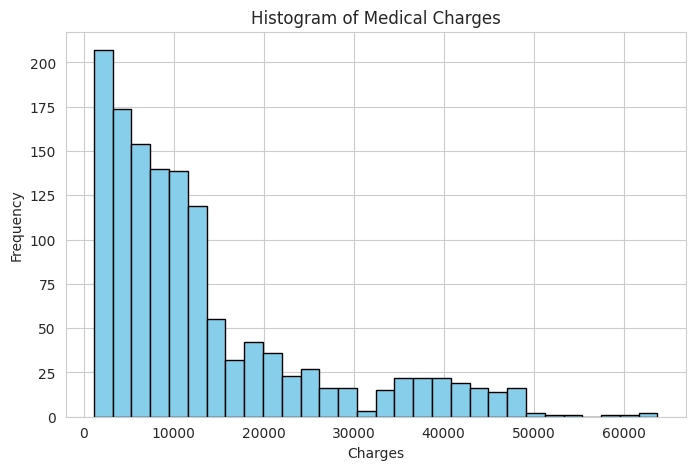

In [ ]:
plt.figure(figsize=(8,5))
plt.hist(df['charges'], bins=30, color='skyblue', edgecolor='black')
plt.title("Histogram of Medical Charges")
plt.xlabel("Charges")
plt.ylabel("Frequency")
plt.show()

### Task B2: Histogram – Distribution of BMI

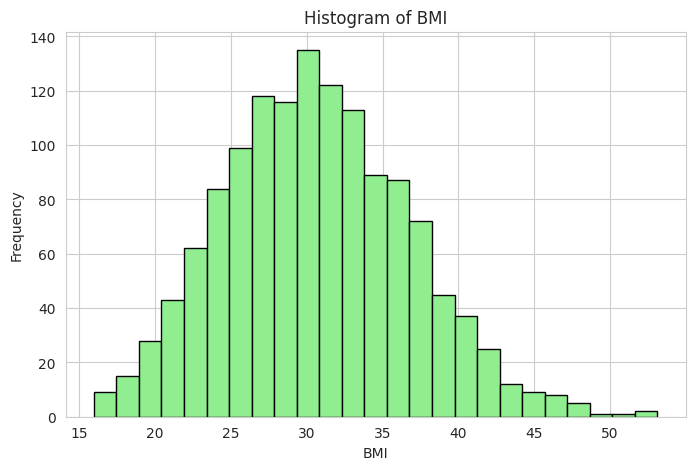

In [ ]:
plt.figure(figsize=(8,5))
plt.hist(df['bmi'], bins=25, color='lightgreen', edgecolor='black')
plt.title("Histogram of BMI")
plt.xlabel("BMI")
plt.ylabel("Frequency")
plt.show()

### Task B3: Box Plot – Charges by Smoker Status (Outlier Detection)

/tmp/ipykernel_2112/2884448120.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='smoker', y='charges', data=df, palette='Set2')


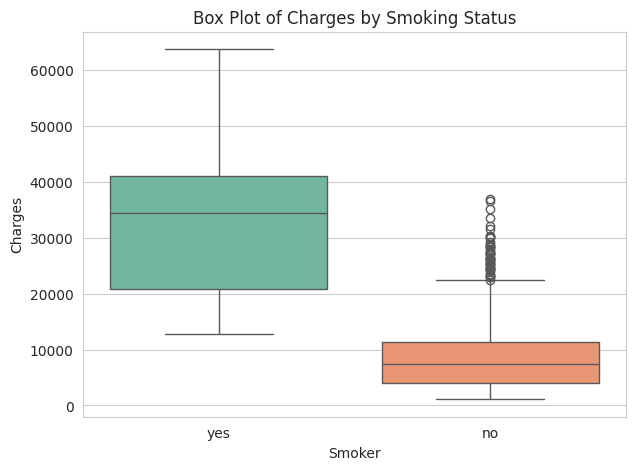

In [ ]:
plt.figure(figsize=(7,5))
sns.boxplot(x='smoker', y='charges', data=df, palette='Set2')
plt.title("Box Plot of Charges by Smoking Status")
plt.xlabel("Smoker")
plt.ylabel("Charges")
plt.show()

### Task B4: Box Plot – BMI Distribution

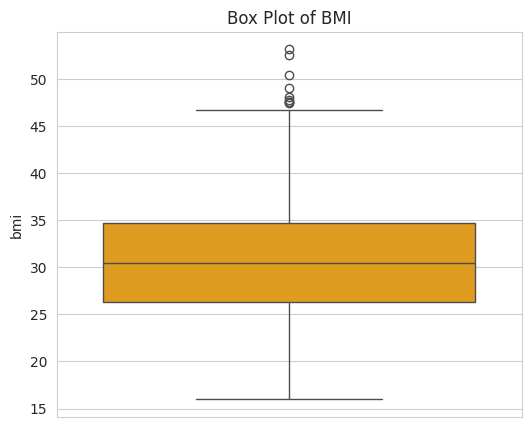

In [ ]:
plt.figure(figsize=(6,5))
sns.boxplot(y=df['bmi'], color='orange')
plt.title("Box Plot of BMI")
plt.show()

### Task B5: Bar Chart – Number of Records per Region

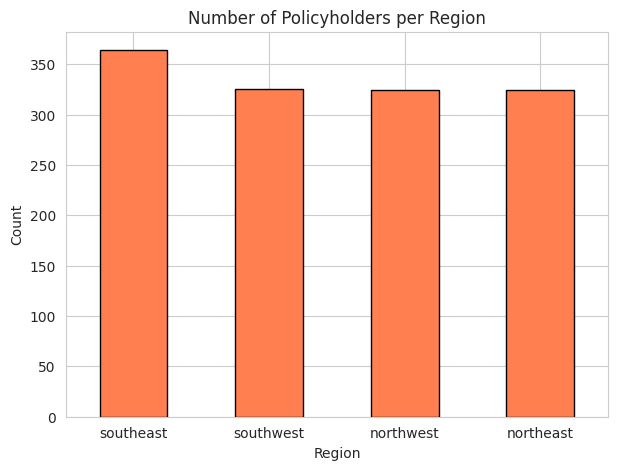

In [ ]:
plt.figure(figsize=(7,5))
df['region'].value_counts().plot(kind='bar', color='coral', edgecolor='black')
plt.title("Number of Policyholders per Region")
plt.xlabel("Region")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

### Task B6: Bar Chart – Average Charges by Region

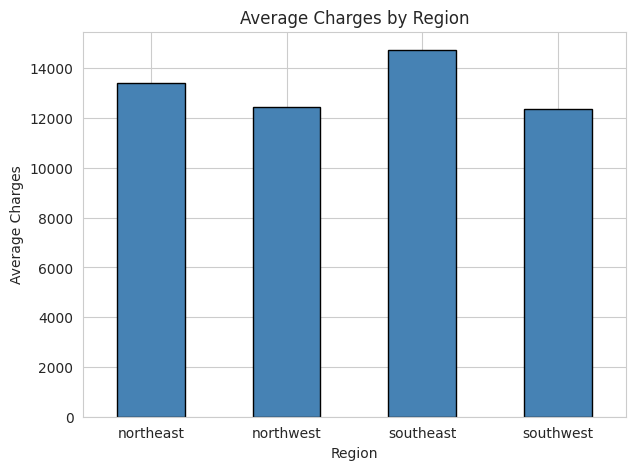

In [ ]:
plt.figure(figsize=(7,5))
df.groupby('region')['charges'].mean().plot(kind='bar', color='steelblue', edgecolor='black')
plt.title("Average Charges by Region")
plt.xlabel("Region")
plt.ylabel("Average Charges")
plt.xticks(rotation=0)
plt.show()

### Task B7: Pie Chart – Proportion of Smokers vs Non-Smokers

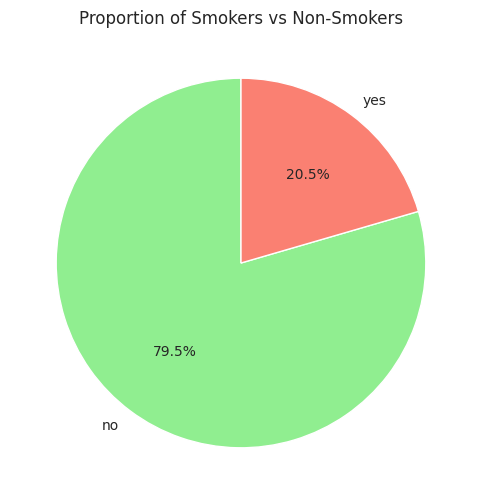

In [ ]:
plt.figure(figsize=(6,6))
df['smoker'].value_counts().plot(kind='pie', autopct='%1.1f%%',
                                  colors=['lightgreen','salmon'], startangle=90)
plt.title("Proportion of Smokers vs Non-Smokers")
plt.ylabel("")
plt.show()

### Task B8: Pie Chart – Proportion of Male vs Female

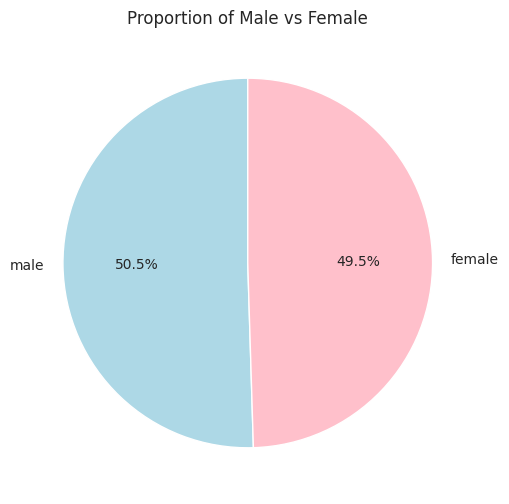

In [ ]:
plt.figure(figsize=(6,6))
df['sex'].value_counts().plot(kind='pie', autopct='%1.1f%%',
                               colors=['lightblue','pink'], startangle=90)
plt.title("Proportion of Male vs Female")
plt.ylabel("")
plt.show()

### Task B9: Scatter Plot – Age vs Charges

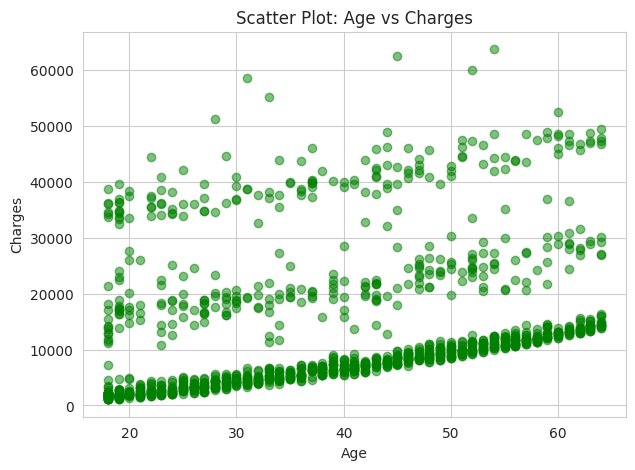

In [ ]:
plt.figure(figsize=(7,5))
plt.scatter(df['age'], df['charges'], alpha=0.5, c='green')
plt.title("Scatter Plot: Age vs Charges")
plt.xlabel("Age")
plt.ylabel("Charges")
plt.show()

### Task B10: Scatter Plot – BMI vs Charges (colored by Smoker)

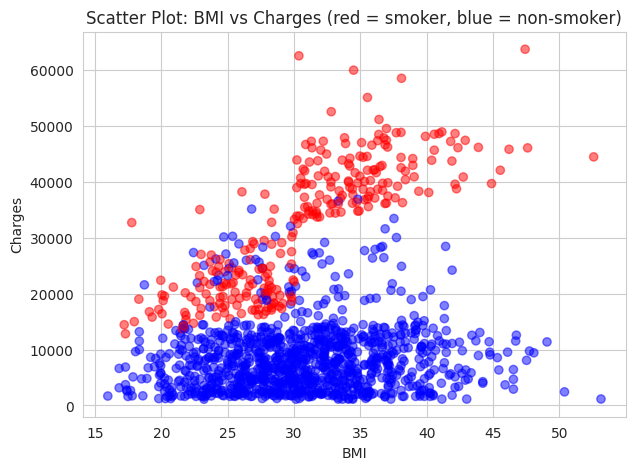

In [ ]:
plt.figure(figsize=(7,5))
colors = df['smoker'].map({'yes':'red','no':'blue'})
plt.scatter(df['bmi'], df['charges'], c=colors, alpha=0.5)
plt.title("Scatter Plot: BMI vs Charges (red = smoker, blue = non-smoker)")
plt.xlabel("BMI")
plt.ylabel("Charges")
plt.show()

### Task B11: Line Chart – Average Charges by Age

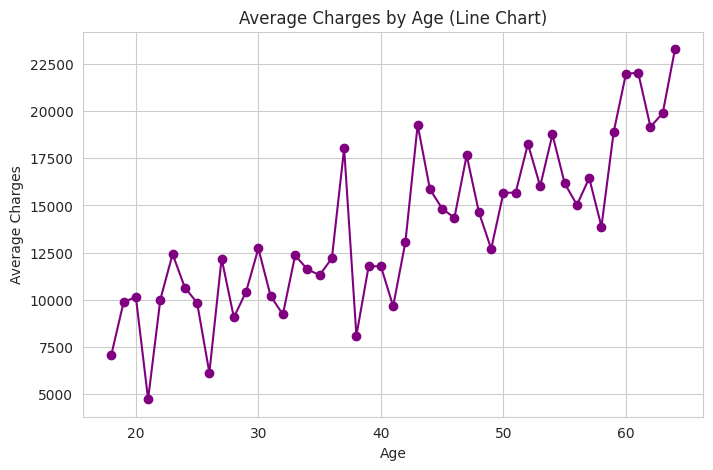

In [ ]:
plt.figure(figsize=(8,5))
df.groupby('age')['charges'].mean().plot(kind='line', marker='o', color='purple')
plt.title("Average Charges by Age (Line Chart)")
plt.xlabel("Age")
plt.ylabel("Average Charges")
plt.show()

### Task B12: Correlation Heatmap

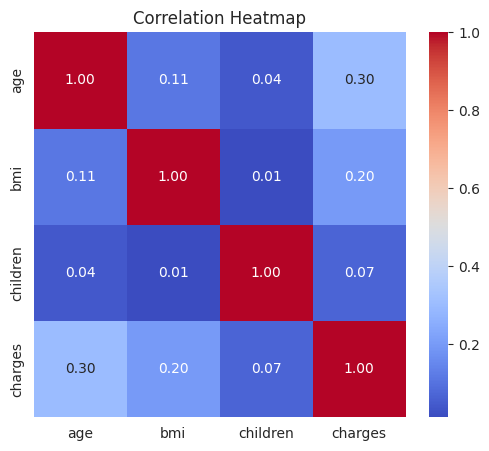

In [ ]:
plt.figure(figsize=(6,5))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

# Practical 4: Central Limit Theorem & Point Estimation

**Aim:** To demonstrate the Central Limit Theorem through repeated sampling and estimate
population parameters using sample statistics and point estimation techniques.

We treat the entire `charges` column (1337 records) as our **population**.

### Task 1: Define the Population & its True Parameters

In [ ]:
population = df['charges'].values

pop_mean = population.mean()
pop_std = population.std()
pop_var = population.var()

print("Population size   :", len(population))
print("Population Mean   :", pop_mean)
print("Population Std Dev:", pop_std)
print("Population Variance:", pop_var)

Population size   : 1337
Population Mean   : 13279.121486655948
Population Std Dev: 12105.829878868954
Population Variance: 146551117.05611628


### Task 2: Visualize the Population Distribution (Skewed / Non-Normal)

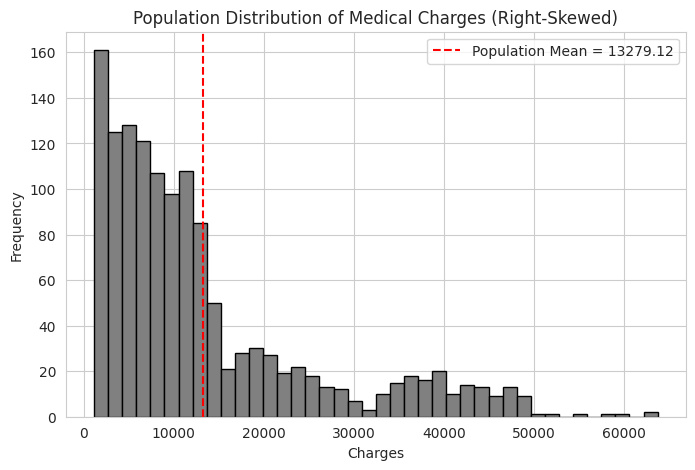

In [ ]:
plt.figure(figsize=(8,5))
plt.hist(population, bins=40, color='gray', edgecolor='black')
plt.axvline(pop_mean, color='red', linestyle='--', label=f'Population Mean = {pop_mean:.2f}')
plt.title("Population Distribution of Medical Charges (Right-Skewed)")
plt.xlabel("Charges")
plt.ylabel("Frequency")
plt.legend()
plt.show()

### Task 3: Repeated Sampling – Draw Many Samples & Record Sample Means

We repeatedly draw random samples of a fixed size `n` from the population (1000 times),
compute the mean of each sample, and study the distribution of these **sample means**.

In [ ]:
def generate_sampling_distribution(population, sample_size, num_samples=1000, seed=42):
    rng = np.random.default_rng(seed)
    sample_means = []
    for _ in range(num_samples):
        sample = rng.choice(population, size=sample_size, replace=False)
        sample_means.append(sample.mean())
    return np.array(sample_means)

# Example: sample size = 30
sample_means_30 = generate_sampling_distribution(population, sample_size=30)
print("Mean of sample means (n=30)  :", sample_means_30.mean())
print("Std Dev of sample means (n=30):", sample_means_30.std())

Mean of sample means (n=30)  : 13232.068250983366
Std Dev of sample means (n=30): 2161.569952025524


### Task 4: Demonstrate CLT – Compare Sampling Distributions for Different Sample Sizes

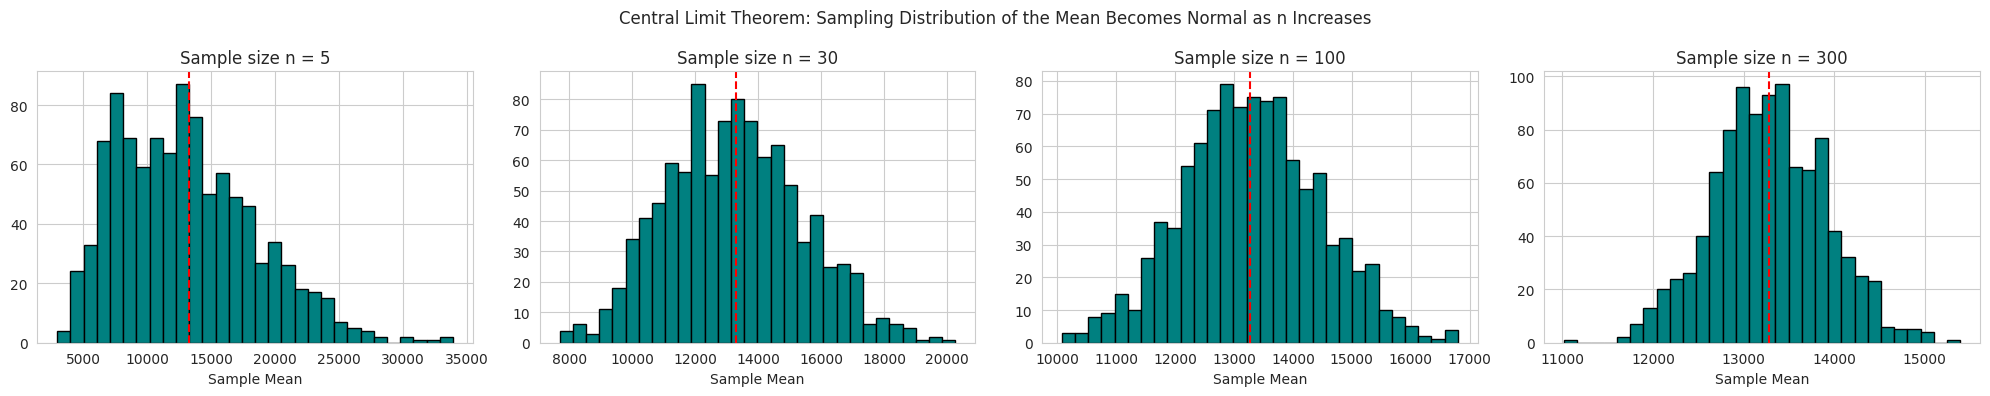

In [ ]:
sample_sizes = [5, 30, 100, 300]
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

for i, n in enumerate(sample_sizes):
    means = generate_sampling_distribution(population, sample_size=n)
    axes[i].hist(means, bins=30, color='teal', edgecolor='black')
    axes[i].axvline(pop_mean, color='red', linestyle='--')
    axes[i].set_title(f"Sample size n = {n}")
    axes[i].set_xlabel("Sample Mean")

plt.suptitle("Central Limit Theorem: Sampling Distribution of the Mean Becomes Normal as n Increases")
plt.tight_layout()
plt.show()

### Task 5: Verify CLT Numerically – Compare Sample-Mean Std Dev to Theoretical Standard Error

In [ ]:
print(f"{'n':>6} | {'Mean of sample means':>22} | {'Std of sample means':>20} | {'Theoretical SE (pop_std/sqrt(n))':>32}")
for n in sample_sizes:
    means = generate_sampling_distribution(population, sample_size=n)
    theoretical_se = pop_std / np.sqrt(n)
    print(f"{n:>6} | {means.mean():>22.2f} | {means.std():>20.2f} | {theoretical_se:>32.2f}")

     n |   Mean of sample means |  Std of sample means | Theoretical SE (pop_std/sqrt(n))
     5 |               13038.96 |              5367.23 |                          5413.89
    30 |               13232.07 |              2161.57 |                          2210.21
   100 |               13286.43 |              1156.04 |                          1210.58
   300 |               13282.50 |               621.01 |                           698.93


### Task 6: Point Estimation of Population Parameters

Using a **single random sample**, estimate the population mean and variance (point estimates),
and compare them to the true population values.

In [ ]:
rng = np.random.default_rng(7)
sample_size = 50
sample = rng.choice(population, size=sample_size, replace=False)

point_estimate_mean = sample.mean()          # estimator for population mean
point_estimate_var  = sample.var(ddof=1)      # unbiased estimator for population variance (n-1)
point_estimate_std  = sample.std(ddof=1)

print("Sample size                 :", sample_size)
print("Point Estimate of Mean      :", point_estimate_mean, " (True Population Mean:", pop_mean, ")")
print("Point Estimate of Variance  :", point_estimate_var, " (True Population Variance:", pop_var, ")")
print("Point Estimate of Std Dev   :", point_estimate_std, " (True Population Std Dev:", pop_std, ")")

Sample size                 : 50
Point Estimate of Mean      : 14010.760337599997  (True Population Mean: 13279.121486655948 )
Point Estimate of Variance  : 139506596.47281978  (True Population Variance: 146551117.05611628 )
Point Estimate of Std Dev   : 11811.291058678546  (True Population Std Dev: 12105.829878868954 )


### Task 7: Interval Estimate – 95% Confidence Interval for the Population Mean

In [ ]:
standard_error = point_estimate_std / np.sqrt(sample_size)
z_critical = 1.96  # for 95% confidence

margin_of_error = z_critical * standard_error
ci_lower = point_estimate_mean - margin_of_error
ci_upper = point_estimate_mean + margin_of_error

print(f"Standard Error       : {standard_error:.2f}")
print(f"Margin of Error      : {margin_of_error:.2f}")
print(f"95% Confidence Interval for Population Mean: ({ci_lower:.2f}, {ci_upper:.2f})")
print(f"True Population Mean : {pop_mean:.2f}  -->  Falls inside CI: {ci_lower <= pop_mean <= ci_upper}")

Standard Error       : 1670.37
Margin of Error      : 3273.92
95% Confidence Interval for Population Mean: (10736.84, 17284.68)
True Population Mean : 13279.12  -->  Falls inside CI: True


### Task 8: Effect of Sample Size on Point Estimate Accuracy

In [ ]:
sizes_to_test = [10, 30, 50, 100, 300, 600]
print(f"{'Sample Size':>12} | {'Estimated Mean':>16} | {'Absolute Error':>16}")
for n in sizes_to_test:
    s = rng.choice(population, size=n, replace=False)
    est_mean = s.mean()
    error = abs(est_mean - pop_mean)
    print(f"{n:>12} | {est_mean:>16.2f} | {error:>16.2f}")

 Sample Size |   Estimated Mean |   Absolute Error
          10 |          9829.82 |          3449.30
          30 |         12038.90 |          1240.22
          50 |         11614.68 |          1664.44
         100 |         12508.89 |           770.23
         300 |         12408.61 |           870.51
         600 |         13320.26 |            41.14


Practical-05:

In [ ]:
#Covariance Matrix
numerical_data = df[["age", "bmi", "children", "charges"]]

covariance = numerical_data.cov()

print("Covariance Matrix:")
print(covariance)

Covariance Matrix:
                   age           bmi    children       charges
age         197.243282      9.368233    0.703268  5.073683e+04
bmi           9.368233     37.215715    0.093805  1.465763e+04
children      0.703268      0.093805    1.453402  9.838780e+02
charges   50736.833698  14657.628526  983.878025  1.466608e+08


In [ ]:
#Calculate Correlation
correlation = numerical_data.corr()

print("Correlation Matrix:")
print(correlation)

Correlation Matrix:
               age       bmi  children   charges
age       1.000000  0.109344  0.041536  0.298308
bmi       0.109344  1.000000  0.012755  0.198401
children  0.041536  0.012755  1.000000  0.067389
charges   0.298308  0.198401  0.067389  1.000000


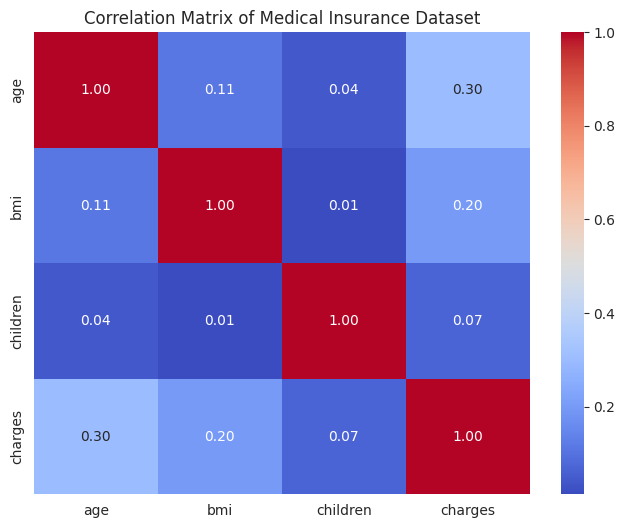

In [ ]:
#Visualize the Correlation Matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Medical Insurance Dataset")
plt.show()

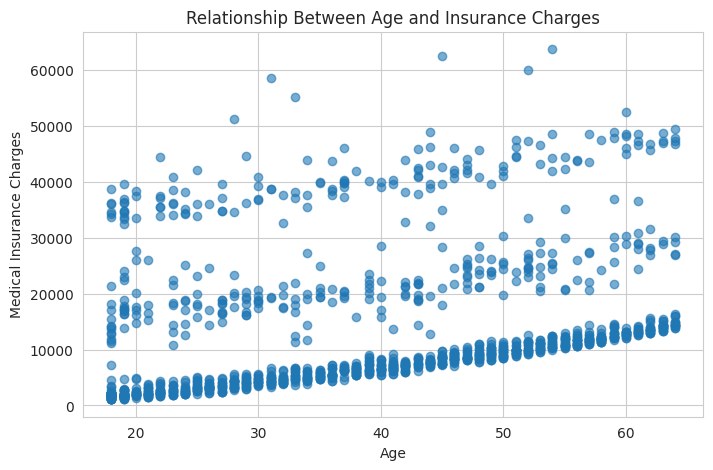

In [ ]:
#Scatter Plot of Age and Insurance Charges
plt.figure(figsize=(8, 5))

plt.scatter(df["age"], df["charges"], alpha=0.6)

plt.xlabel("Age")
plt.ylabel("Medical Insurance Charges")
plt.title("Relationship Between Age and Insurance Charges")

plt.show()

Practical 6 — Part C: Hypothesis Testing for Correlation

In [ ]:
#Pearson Correlation Test
from scipy.stats import pearsonr

r, p_value = pearsonr(df["age"], df["charges"])

print("Pearson Correlation:", r)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: Significant linear correlation exists.")
else:
    print("Fail to reject H0: Insufficient evidence of linear correlation.")

Pearson Correlation: 0.29830821250978634
P-value: 6.975748762691733e-29
Reject H0: Significant linear correlation exists.


In [ ]:
#Spearman Correlation Test
from scipy.stats import spearmanr

rho, p_value = spearmanr(df["age"], df["charges"])

print("Spearman Correlation:", rho)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: Significant monotonic relationship exists.")
else:
    print("Fail to reject H0: Insufficient evidence of a monotonic relationship.")

Spearman Correlation: 0.5335232787189862
P-value: 3.187755650322475e-99
Reject H0: Significant monotonic relationship exists.


In [ ]:
#Compare Pearson and Spearman Correlations
variables = [
    ("age", "charges"),
    ("bmi", "charges"),
    ("children", "charges")
]

for x, y in variables:
    pearson_r, pearson_p = pearsonr(df[x], df[y])
    spearman_r, spearman_p = spearmanr(df[x], df[y])

    print("\nVariables:", x, "and", y)
    print("Pearson r:", round(pearson_r, 4))
    print("Pearson p-value:", pearson_p)
    print("Spearman rho:", round(spearman_r, 4))
    print("Spearman p-value:", spearman_p)


Variables: age and charges
Pearson r: 0.2983
Pearson p-value: 6.975748762691733e-29
Spearman rho: 0.5335
Spearman p-value: 3.187755650322475e-99

Variables: bmi and charges
Pearson r: 0.1984
Pearson p-value: 2.4680404264513685e-13
Spearman rho: 0.1196
Spearman p-value: 1.1637179203181515e-05

Variables: children and charges
Pearson r: 0.0674
Pearson p-value: 0.013717026292986805
Spearman rho: 0.1322
Spearman p-value: 1.2303764274728683e-06


Hypothesis Testing Using T-Test, Chi-Square Test and ANOVA

In [ ]:
#One-Sample T-Test
from scipy.stats import ttest_1samp

charges = df["charges"].dropna()

reference_mean = 10000

t_stat, p_value = ttest_1samp(
    charges,
    popmean=reference_mean
)

print("Sample Mean:", charges.mean())
print("Reference Mean:", reference_mean)
print("T-Statistic:", t_stat)
print("P-Value:", p_value)

if p_value < 0.05:
    print("Reject H0: Mean charges differ significantly from $10,000.")
else:
    print("Fail to reject H0: Insufficient evidence of a difference.")

Sample Mean: 13279.121486655948
Reference Mean: 10000
T-Statistic: 9.900706115483878
P-Value: 2.378374652849273e-22
Reject H0: Mean charges differ significantly from $10,000.


In [ ]:
#Two-Sample T-Test
from scipy.stats import ttest_ind

smokers = df[df["smoker"] == "yes"]["charges"].dropna()
non_smokers = df[df["smoker"] == "no"]["charges"].dropna()

print("Mean Charges of Smokers:", smokers.mean())
print("Mean Charges of Non-Smokers:", non_smokers.mean())

t_stat, p_value = ttest_ind(
    smokers,
    non_smokers,
    equal_var=False
)

print("T-Statistic:", t_stat)
print("P-Value:", p_value)

if p_value < 0.05:
    print("Reject H0: The group means differ significantly.")
else:
    print("Fail to reject H0: Insufficient evidence of a difference.")

Mean Charges of Smokers: 32050.23183153284
Mean Charges of Non-Smokers: 8440.660306508937
T-Statistic: 32.7423097372529
P-Value: 6.261720774727631e-103
Reject H0: The group means differ significantly.


In [ ]:
#Demonstration of Paired T-Test
from scipy.stats import ttest_rel
import numpy as np
before = np.array([
    5000, 6200, 7100, 8000, 9500,
    10200, 11000, 12500, 13200, 14000
])

after = np.array([
    4800, 6000, 7000, 7900, 9100,
    9900, 10900, 12100, 13000, 13700
])

t_stat, p_value = ttest_rel(before, after)

print("Mean Before:", before.mean())
print("Mean After:", after.mean())
print("T-Statistic:", t_stat)
print("P-Value:", p_value)

if p_value < 0.05:
    print("Reject H0: Significant paired difference exists.")
else:
    print("Fail to reject H0: Insufficient evidence of a difference.")

Mean Before: 9670.0
Mean After: 9440.0
T-Statistic: 6.272727272727272
P-Value: 0.00014563278012850932
Reject H0: Significant paired difference exists.


In [ ]:
#Chi-Square Test
from scipy.stats import chi2_contingency

# Create a contingency table
table = pd.crosstab(df["sex"], df["smoker"])

print("Contingency Table:")
print(table)

chi2, p_value, dof, expected = chi2_contingency(table)

print("\nChi-Square Statistic:", chi2)
print("Degrees of Freedom:", dof)
print("P-Value:", p_value)

print("\nExpected Frequencies:")
print(pd.DataFrame(
    expected,
    index=table.index,
    columns=table.columns
))

if p_value < 0.05:
    print("Reject H0: Sex and smoking status are associated.")
else:
    print("Fail to reject H0: Insufficient evidence of an association.")

Contingency Table:
smoker   no  yes
sex             
female  547  115
male    516  159

Chi-Square Statistic: 7.469139330086637
Degrees of Freedom: 1
P-Value: 0.0062765550120107375

Expected Frequencies:
smoker          no         yes
sex                           
female  526.332087  135.667913
male    536.667913  138.332087
Reject H0: Sex and smoking status are associated.


In [ ]:
#One-Way ANOVA
from scipy.stats import f_oneway

northeast = df[df["region"] == "northeast"]["charges"].dropna()
northwest = df[df["region"] == "northwest"]["charges"].dropna()
southeast = df[df["region"] == "southeast"]["charges"].dropna()
southwest = df[df["region"] == "southwest"]["charges"].dropna()

f_stat, p_value = f_oneway(
    northeast,
    northwest,
    southeast,
    southwest
)

print("Mean Northeast:", northeast.mean())
print("Mean Northwest:", northwest.mean())
print("Mean Southeast:", southeast.mean())
print("Mean Southwest:", southwest.mean())

print("\nF-Statistic:", f_stat)
print("P-Value:", p_value)

if p_value < 0.05:
    print("Reject H0: At least one regional mean differs.")
else:
    print("Fail to reject H0: Insufficient evidence of a difference.")

Mean Northeast: 13406.384516385804
Mean Northwest: 12450.840843950617
Mean Southeast: 14735.411437609888
Mean Southwest: 12346.937377292308

F-Statistic: 2.926139903662777
P-Value: 0.03276288025444947
Reject H0: At least one regional mean differs.


Multiple Linear Regression for Medical Insurance Cost Prediction

In [ ]:
# Step 1: Import libraries

import pandas as pd
import numpy as np
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
# Step 2: Prepare dataset

X = df.drop("charges", axis=1)
y = df["charges"]

numeric_features = ["age", "bmi", "children"]
categorical_features = ["sex", "smoker", "region"]

# Handle numerical and categorical columns
numeric_transformer = SimpleImputer(strategy="median")

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1069
Testing records: 268


In [ ]:
# Step 3: Train and compare models

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, random_state=42
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}

results = []
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    results.append([name, mae, mse, rmse, r2])
    trained_models[name] = pipeline

results_df = pd.DataFrame(
    results,
    columns=["Model", "MAE", "MSE", "RMSE", "R2"]
)

display(results_df.round(2))

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,4177.05,35478020.68,5956.34,0.81
1,Ridge Regression,4185.52,35566368.05,5963.75,0.81
2,Random Forest,2563.60,21604001.05,4648.01,0.88
3,Gradient Boosting,2535.03,18249040.32,4271.89,0.90


In [ ]:
# Step 4: Select and save the best model

# Select the model with the lowest RMSE
best_model_name = results_df.loc[
    results_df["RMSE"].idxmin(), "Model"
]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

joblib.dump(best_model, "best_insurance_model.joblib")

print("Best model saved successfully!")

Best Model: Gradient Boosting
Best model saved successfully!


In [ ]:
# Step 5: Download the saved model to your computer

from google.colab import files

files.download("best_insurance_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import sklearn
print(sklearn.__version__)

1.6.1


In [ ]:
!pip install scikit-learn==1.9.1